# 04 · İş Yorumu: Maliyet, Eşik Seçimi ve Kullanım Önerisi

**Amaç:** Modelin skorunu bir iş kararına çevirmek. "Hangi eşiğin üzerindeki talepler
incelemeye gitmeli?" sorusunun cevabı istatistiksel değil **ekonomiktir**: yanlış alarmın
ve kaçırılan sahtekârlığın maliyetine bağlıdır.

İki hata türü, iki farklı maliyet:

| Hata | Ne olur | Maliyeti kim öder |
|---|---|---|
| **Yanlış alarm** (meşru talep incelemeye gider) | İnceleme emeği boşa gider, ödeme gecikir | Şirket (operasyon) ve dürüst müşteri (memnuniyet) |
| **Kaçırılan sahtekârlık** (sahte talep ödenir) | Haksız tazminat ödenir | Şirket; dolaylı olarak prim artışıyla tüm müşteriler |

> Bu defter, `02_modeling.ipynb` tarafından kaydedilen tahminleri kullanır. Eşikler
> eğitim setindeki kat dışı (out-of-fold) tahminlerle seçilir, sonuçlar test setinde
> raporlanır.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve

from src import config, data, evaluation as ev, plotting

plotting.set_style()
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

oof_path = config.MODELS_DIR / "train_oof_predictions.csv"
if not oof_path.exists():
    raise FileNotFoundError("Run notebooks/02_modeling.ipynb first: it saves the predictions.")
oof = pd.read_csv(oof_path, index_col="row_id")
test = pd.read_csv(config.MODELS_DIR / "test_predictions.csv", index_col="row_id")
df = data.load_clean()
print(f"Out-of-fold predictions: {len(oof):,} claims | test predictions: {len(test):,} claims, "
      f"{int(test['y'].sum())} frauds")

Out-of-fold predictions: 12,335 claims | test predictions: 3,084 claims, 185 frauds


## 1. Sınırlı inceleme kapasitesi: en şüpheli talepler

Çoğu şirkette özel inceleme birimi taleplerin yalnızca küçük bir kısmına bakabilir.
Soru: "Skora göre en üstteki %k talebi incelersek ne yakalarız?"

In [2]:
top_k = {name: ev.top_k_table(test["y"], test[col])
         for name, col in [("LightGBM", "lightgbm"), ("Logistic regression", "logreg")]}
top_k["LightGBM"]

,reviewed_share,claims_reviewed,frauds_caught,precision,recall,lift
0,0.010,31,11,0.355,0.059,5.915
1,0.020,62,16,0.258,0.086,4.302
2,0.050,154,33,0.214,0.178,3.572
3,0.100,308,58,0.188,0.314,3.139
4,0.200,617,104,0.169,0.562,2.810
5,0.300,925,143,0.155,0.773,2.577


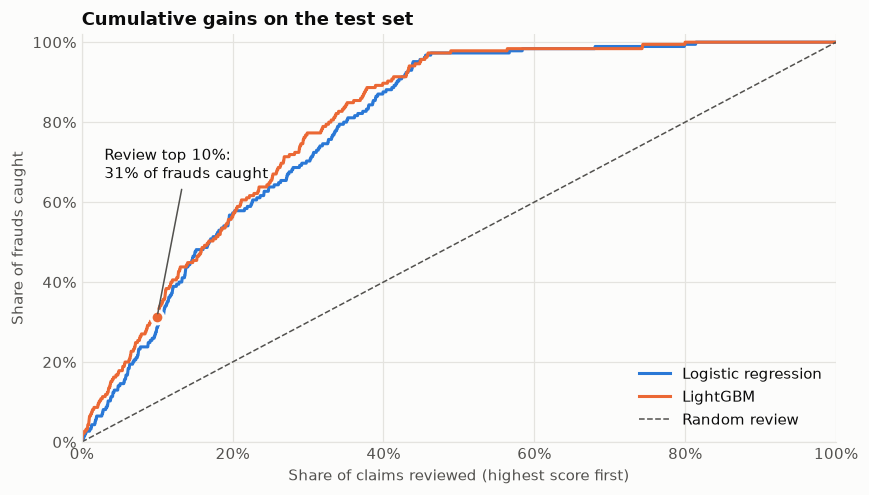

In [3]:
def gains_curve(y_true, score):
    """Cumulative share of frauds caught as claims are reviewed from the highest score down."""
    order = np.argsort(-np.asarray(score), kind="stable")
    caught = np.cumsum(np.asarray(y_true)[order]) / np.sum(y_true)
    reviewed = np.arange(1, len(order) + 1) / len(order)
    return np.concatenate([[0], reviewed]), np.concatenate([[0], caught])


fig, ax = plt.subplots(figsize=(8, 4.6))
for name, col, color in [("Logistic regression", "logreg", plotting.COLOR_LOGREG),
                         ("LightGBM", "lightgbm", plotting.COLOR_LGBM)]:
    reviewed, caught = gains_curve(test["y"], test[col])
    ax.plot(reviewed, caught, color=color, label=name)
ax.plot([0, 1], [0, 1], color=plotting.INK_MUTED, linestyle="--", linewidth=1, label="Random review")
row10 = top_k["LightGBM"].set_index("reviewed_share").loc[0.10]
ax.scatter([0.10], [row10["recall"]], s=70, color=plotting.COLOR_LGBM, edgecolor=plotting.SURFACE,
           linewidth=2, zorder=3)
ax.annotate(f"Review top 10%:\n{row10['recall']:.0%} of frauds caught", (0.10, row10["recall"]),
            xytext=(0.03, 0.66), color=plotting.INK,
            arrowprops=dict(arrowstyle="-", color=plotting.INK_MUTED))
ax.set_xlabel("Share of claims reviewed (highest score first)")
ax.set_ylabel("Share of frauds caught")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
plotting.pct_axis(ax, "x")
plotting.pct_axis(ax, "y")
ax.set_title("Cumulative gains on the test set")
ax.legend(loc="lower right")
fig.tight_layout()
plotting.save_fig(fig, "13_cumulative_gains")
plt.show()

In [4]:
lgbm_k = top_k["LightGBM"].set_index("reviewed_share")
logreg_k = top_k["Logistic regression"].set_index("reviewed_share")
comparison = pd.DataFrame({
    "claims_reviewed": lgbm_k["claims_reviewed"],
    "lightgbm_precision": lgbm_k["precision"], "logreg_precision": logreg_k["precision"],
    "lightgbm_recall": lgbm_k["recall"], "logreg_recall": logreg_k["recall"],
    "lightgbm_lift": lgbm_k["lift"],
})
comparison

,claims_reviewed,lightgbm_precision,logreg_precision,lightgbm_recall,logreg_recall,lightgbm_lift
reviewed_share,,,,,,
0.010,31,0.355,0.161,0.059,0.027,5.915
0.020,62,0.258,0.194,0.086,0.065,4.302
0.050,154,0.214,0.169,0.178,0.141,3.572
0.100,308,0.188,0.172,0.314,0.286,3.139
0.200,617,0.169,0.172,0.562,0.573,2.810
0.300,925,0.155,0.141,0.773,0.703,2.577


- **En üstteki %1** (31 talep): LightGBM'de 11'i sahte, precision %35,5; rastgele
  incelemeye göre yaklaşık 6 kat daha verimli. Lojistik regresyonda aynı dilimde %16.
- **En üstteki %10** (308 talep): precision %18,8; sahtekârlıkların %31'i yakalanıyor.
- **%20 ve sonrası:** iki model arasında fark kalmıyor.

Modelin katkısı listenin **en başında**: kapasite ne kadar kısıtlıysa LightGBM o kadar
değerli. Not: %1'lik dilim yalnızca 31 talep; bu sayılardaki belirsizlik yüksektir.

## 2. Olasılıklar güvenilir mi? (Kalibrasyon)

Maliyet temelli karar için modelin "%20" dediği taleplerin gerçekten yaklaşık %20'sinin
sahte olması gerekir. Model yeniden örnekleme veya sınıf ağırlığı olmadan eğitildiği
için (defter 02) olasılıkların gerçek orana yakın olması beklenir.

 mean_predicted  observed_fraud_rate
          0.009                0.000
          0.012                0.003
          0.013                0.005
          0.015                0.003
          0.056                0.049
          0.095                0.109
          0.116                0.117
          0.167                0.194

Mean predicted probability: 0.060 | observed fraud rate: 0.060


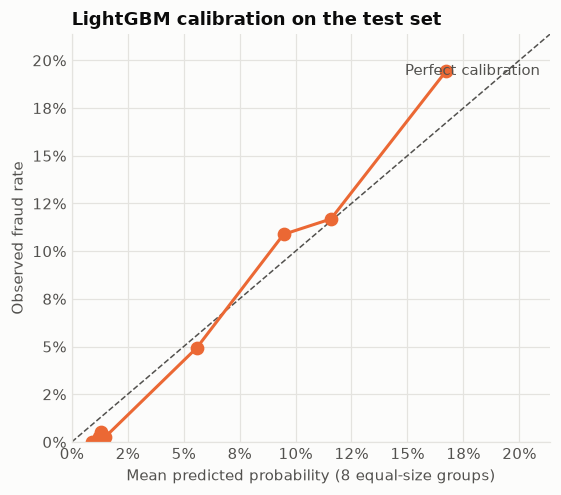

In [5]:
observed, predicted = calibration_curve(test["y"], test["lightgbm"], n_bins=8, strategy="quantile")
calibration = pd.DataFrame({"mean_predicted": predicted, "observed_fraud_rate": observed})
print(calibration.round(3).to_string(index=False))
print(f"\nMean predicted probability: {test['lightgbm'].mean():.3f} | observed fraud rate: {test['y'].mean():.3f}")

fig, ax = plt.subplots(figsize=(5.2, 4.6))
limit = max(predicted.max(), observed.max()) * 1.1
ax.plot([0, limit], [0, limit], color=plotting.INK_MUTED, linestyle="--", linewidth=1)
ax.text(limit * 0.98, limit * 0.9, "Perfect calibration", ha="right", color=plotting.INK_MUTED)
ax.plot(predicted, observed, marker="o", markersize=8, color=plotting.COLOR_LGBM)
ax.set_xlabel("Mean predicted probability (8 equal-size groups)")
ax.set_ylabel("Observed fraud rate")
plotting.pct_axis(ax, "x")
plotting.pct_axis(ax, "y")
ax.set_xlim(0, limit)
ax.set_ylim(0, limit)
ax.set_title("LightGBM calibration on the test set")
fig.tight_layout()
plotting.save_fig(fig, "14_calibration")
plt.show()

Noktalar köşegene yakın: model olasılıkları kabaca kalibre. Düşük riskli gruplarda model
riski bir miktar yüksek tahmin ediyor (≈ %1 tahmin, gözlenen %0–0,5), yüksek riskli
grupta bir miktar düşük (≈ %17 tahmin, gözlenen ≈ %19). Bu, aşağıdaki maliyet analizinde
teorik eşiğin kullanılabilir olduğunu gösterir.

## 3. Maliyet modeli

Gerçek maliyetler şirkete özeldir ve bu veri setinde **hasar tutarı yoktur**. Bu yüzden
sonuçlar tek bir parametreye bağlı olarak sunulur:

**Kayıp oranı `r` = ortalama sahte tazminat tutarı / bir talebi inceleme maliyeti**

Birim: bir inceleme = 1 birim.

| Karar | Gerçek durum | Maliyet |
|---|---|---|
| İncele | Meşru | 1 (boşa inceleme) |
| İncele | Sahte | 1 (inceleme; tazminat ödenmez) |
| İnceleme | Sahte | `r` (haksız tazminat) |
| İnceleme | Meşru | 0 |

**Teorik sonuç:** Bir talebi incelemek, sahtekârlık olasılığı `p` için `p · r > 1`
olduğunda kârlıdır. Yani kalibre bir modelde en iyi eşik **`1 / r`**'dir. Örneğin sahte
bir tazminat ortalama 10 inceleme maliyetine eşitse, %10'un üzerinde olasılık verilen
her talep incelenmelidir.

Varsayımlar: inceleme sahtekârlığı kesin tespit eder;
gecikmenin müşteri memnuniyetine maliyeti ayrıca sayılmaz; tüm sahte talepler aynı
tutardadır.

In [6]:
loss_ratios = [5, 10, 20, 50]
rule_flag_test = ((df.loc[test.index, "Fault"] == "Policy Holder")
                  & (df.loc[test.index, "BasePolicy"] != "Liability")).astype(float)


def cost_per_1000(y_true, flagged, loss_ratio):
    """Total cost per 1,000 claims for a given set of flagged claims."""
    y_true, flagged = np.asarray(y_true), np.asarray(flagged).astype(bool)
    missed = np.sum(~flagged & (y_true == 1))
    return 1000 * (flagged.sum() + loss_ratio * missed) / len(y_true)


rows = []
for r in loss_ratios:
    # Threshold chosen on out-of-fold predictions, then applied unchanged to the test set.
    curve = ev.cost_curve(oof["y"], oof["oof_lightgbm"], r)
    threshold = float(curve.loc[curve["cost_per_1000"].idxmin(), "threshold"])
    lgbm = ev.threshold_metrics(test["y"], test["lightgbm"], threshold)

    curve_lr = ev.cost_curve(oof["y"], oof["oof_logreg"], r)
    threshold_lr = float(curve_lr.loc[curve_lr["cost_per_1000"].idxmin(), "threshold"])

    costs = {
        "investigate nothing": cost_per_1000(test["y"], np.zeros(len(test)), r),
        "investigate everything": cost_per_1000(test["y"], np.ones(len(test)), r),
        "two-variable rule": cost_per_1000(test["y"], rule_flag_test, r),
        "logistic regression": cost_per_1000(test["y"], test["logreg"] >= threshold_lr, r),
        "LightGBM": cost_per_1000(test["y"], test["lightgbm"] >= threshold, r),
    }
    rows.append({"loss_ratio": r, "theoretical_threshold": 1 / r, "chosen_threshold": threshold,
                 "flagged_share": lgbm["flagged_share"], "precision": lgbm["precision"],
                 "recall": lgbm["recall"], **{f"cost: {k}": v for k, v in costs.items()}})
scenarios = pd.DataFrame(rows).set_index("loss_ratio")
scenarios[["theoretical_threshold", "chosen_threshold", "flagged_share", "precision", "recall"]]

,theoretical_threshold,chosen_threshold,flagged_share,precision,recall
loss_ratio,,,,,
5,0.200,0.207,0.012,0.342,0.070
10,0.100,0.086,0.363,0.141,0.854
20,0.050,0.047,0.461,0.127,0.973
50,0.020,0.047,0.461,0.127,0.973


In [7]:
cost_columns = [c for c in scenarios.columns if c.startswith("cost: ")]
cost_table = scenarios[cost_columns].rename(columns=lambda c: c.replace("cost: ", ""))
print("Total cost per 1,000 claims on the test set (1 unit = cost of one investigation):")
print(cost_table.round(0).to_string())

best_simple = cost_table[["investigate nothing", "investigate everything", "two-variable rule"]].min(axis=1)
saving = pd.DataFrame({
    "best_alternative_without_model": cost_table[["investigate nothing", "investigate everything",
                                                  "two-variable rule"]].idxmin(axis=1),
    "saving_vs_nothing": 1 - cost_table["LightGBM"] / cost_table["investigate nothing"],
    "saving_vs_best_alternative": 1 - cost_table["LightGBM"] / best_simple,
})
print("\nLightGBM saving:")
print(saving.to_string(float_format=lambda v: f"{v:.1%}"))

Total cost per 1,000 claims on the test set (1 unit = cost of one investigation):
            investigate nothing  investigate everything  two-variable rule  logistic regression  LightGBM
loss_ratio                                                                                               
5                       300.000               1,000.000            467.000              298.000   291.000
10                      600.000               1,000.000            483.000              468.000   451.000
20                    1,200.000               1,000.000            516.000              499.000   493.000
50                    2,999.000               1,000.000            613.000              547.000   542.000

LightGBM saving:
           best_alternative_without_model  saving_vs_nothing  saving_vs_best_alternative
loss_ratio                                                                              
5                     investigate nothing               2.9%                        2.

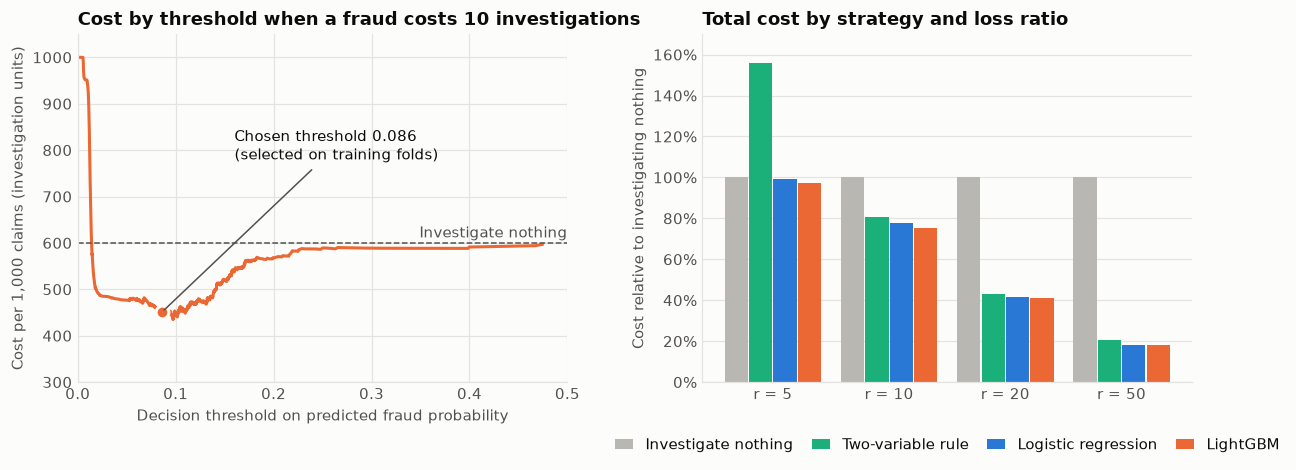

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

ax = axes[0]
r_focus = 10
curve_test = ev.cost_curve(test["y"], test["lightgbm"], r_focus)
curve_test = curve_test[curve_test["threshold"] <= 0.5]
ax.plot(curve_test["threshold"], curve_test["cost_per_1000"], color=plotting.COLOR_LGBM)
chosen = scenarios.loc[r_focus, "chosen_threshold"]
chosen_cost = scenarios.loc[r_focus, "cost: LightGBM"]
ax.scatter([chosen], [chosen_cost], s=70, color=plotting.COLOR_LGBM, edgecolor=plotting.SURFACE,
           linewidth=2, zorder=3)
ax.annotate(f"Chosen threshold {chosen:.3f}\n(selected on training folds)", (chosen, chosen_cost),
            xytext=(0.16, 780), color=plotting.INK,
            arrowprops=dict(arrowstyle="-", color=plotting.INK_MUTED))
nothing = scenarios.loc[r_focus, "cost: investigate nothing"]
ax.axhline(nothing, color=plotting.INK_MUTED, linestyle="--", linewidth=1)
ax.text(0.5, nothing + 12, "Investigate nothing", ha="right", color=plotting.INK_MUTED)
ax.set_xlabel("Decision threshold on predicted fraud probability")
ax.set_ylabel("Cost per 1,000 claims (investigation units)")
ax.set_xlim(0, 0.5)
ax.set_ylim(300, 1050)
ax.set_title(f"Cost by threshold when a fraud costs {r_focus} investigations")

ax = axes[1]
strategies = [("investigate nothing", "#b8b7b2"), ("two-variable rule", plotting.AQUA),
              ("logistic regression", plotting.COLOR_LOGREG), ("LightGBM", plotting.COLOR_LGBM)]
x = np.arange(len(loss_ratios))
width = 0.2
for i, (name, color) in enumerate(strategies):
    relative = cost_table[name] / cost_table["investigate nothing"]
    ax.bar(x + (i - 1.5) * (width + 0.01), relative, width, color=color, label=name.capitalize()
           if name != "LightGBM" else name)
ax.set_xticks(x, [f"r = {r}" for r in loss_ratios])
ax.set_ylim(0, 1.7)
plotting.pct_axis(ax, "y")
ax.set_ylabel("Cost relative to investigating nothing")
ax.set_title("Total cost by strategy and loss ratio")
ax.legend(loc="upper center", ncol=4, bbox_to_anchor=(0.5, -0.12), columnspacing=1.2, handlelength=1.2)
ax.grid(axis="x", visible=False)

fig.tight_layout()
plotting.save_fig(fig, "15_cost_analysis")
plt.show()

**Bulgular**

1. **Teori ile veri uyuşuyor.** Eğitim katlarında maliyeti en aza indiren eşikler teorik
   `1 / r` değerine çok yakın (0,207 ↔ 0,200; 0,086 ↔ 0,100; 0,047 ↔ 0,050). `r = 50`
   için eşik 0,047'de kalıyor, çünkü bu skorun altındaki taleplerde neredeyse hiç
   sahtekârlık yok.
2. **Tasarruf kayıp oranına çok duyarlı.** Hiç inceleme yapmamaya göre toplam maliyet
   `r = 5` için %3, `r = 10` için %25, `r = 20` için %59, `r = 50` için %82 azalıyor.
   Sahte tazminat inceleme maliyetinin yalnızca 5 katıysa, bu veriyle sahtekârlık
   incelemesi neredeyse hiç kazandırmıyor.
3. **Kazancın büyük kısmı basit kuraldan geliyor.** "Kusur poliçe sahibinde ve poliçe
   sorumluluk değil" kuralı tek başına tasarrufun çoğunu sağlıyor. LightGBM'in bu kuralın
   **üzerine** eklediği tasarruf %4–12 arasında. `r ≥ 20` için modelin önerdiği politika
   (taleplerin %46'sını incele) kuralın yaptığıyla (%45) neredeyse aynı.

**Dürüst sonuç:** Bu veride modelin değeri "sahtekârlığı bulmak"tan çok, **inceleme
kuyruğunu sıralamak** ve düşük riskli talepleri güvenle hızlı ödemeye ayırmaktır.
Bir şirkete ilk önerim kuralı hemen devreye almak, modeli ise kısıtlı kapasiteli
özel inceleme birimi için önceliklendirme aracı olarak kullanmak olurdu.

### 3.1 Duyarlılık: inceleme her sahtekârlığı yakalamazsa

Gerçekte inceleme her sahtekârlığı kanıtlayamaz. Tespit oranı `d` ise incelemenin kârlı
olma koşulu `p · r · d > 1`, eşik `1 / (r · d)` olur.

In [9]:
sensitivity = []
for r in loss_ratios:
    for d in [1.0, 0.7, 0.5]:
        curve = ev.cost_curve(oof["y"], oof["oof_lightgbm"], r, detection_rate=d)
        threshold = float(curve.loc[curve["cost_per_1000"].idxmin(), "threshold"])
        on_test = ev.cost_curve(test["y"], test["lightgbm"], r, detection_rate=d, thresholds=[threshold]).iloc[0]
        sensitivity.append({"loss_ratio": r, "detection_rate": d, "theoretical_threshold": min(1.0, 1 / (r * d)),
                            "chosen_threshold": threshold, "flagged_share": on_test["flagged_share"],
                            "recall": on_test["recall"],
                            "saving_vs_nothing": on_test["saving_per_1000"] / (r * 1000 * test["y"].mean())})
pd.DataFrame(sensitivity).set_index(["loss_ratio", "detection_rate"])

theoretical_threshold  chosen_threshold  flagged_share  recall  saving_vs_nothing
loss_ratio detection_rate                                                                                   
5          1.000                           0.200             0.207          0.012   0.070              0.029
           0.700                           0.286             0.281          0.002   0.022              0.008
           0.500                           0.400             0.281          0.002   0.022              0.003
10         1.000                           0.100             0.086          0.363   0.854              0.249
           0.700                           0.143             0.136          0.114   0.384              0.078
           0.500                           0.200             0.207          0.012   0.070              0.015
20         1.000                           0.050             0.047          0.461   0.973              0.589
           0.700                           0.071             0.072          0.419   0.914              0.290
           0.500                           0.100             0.086          0.363   0.854              0.124
50         1.000                           0.020             0.047          0.461   0.973              0.819
           0.700                           0.029             0.047          0.461   0.973              0.527
           0.500                           0.040             0.047          0.461   0.973              0.333

Tespit oranı düştükçe eşik yükselir, incelenen talep sayısı ve tasarruf azalır. Düşük
kayıp oranında (`r = 5`) ve zayıf tespit oranında model neredeyse hiçbir talebi
incelemeye göndermez: bu senaryoda sahtekârlık incelemesi ekonomik değildir.

## 4. Öneri: üç kademeli iş akışı

Tek bir eşik yerine iki eşik: skor, talebi üç yoldan birine yönlendirir. Eşikler eğitim
katlarında seçilen maliyet-optimal değerlerdir (alt eşik `r = 20`, üst eşik `r = 5`
senaryosundan).

In [10]:
low_cut = scenarios.loc[20, "chosen_threshold"]
high_cut = scenarios.loc[5, "chosen_threshold"]
tier = pd.cut(test["lightgbm"], [-np.inf, low_cut, high_cut, np.inf], right=False,
              labels=["1. Fast track (low risk)", "2. Standard review (medium risk)",
                      "3. Special investigation (high risk)"])
tiers = test.groupby(tier, observed=True)["y"].agg(claims="size", frauds="sum")
tiers["share_of_claims"] = tiers["claims"] / len(test)
tiers["fraud_rate"] = tiers["frauds"] / tiers["claims"]
tiers["share_of_all_frauds"] = tiers["frauds"] / test["y"].sum()
print(f"Lower threshold: {low_cut:.3f} | upper threshold: {high_cut:.3f}")
tiers

Lower threshold: 0.047 | upper threshold: 0.207


,claims,frauds,share_of_claims,fraud_rate,share_of_all_frauds
lightgbm,,,,,
1. Fast track (low risk),1663,5,0.539,0.003,0.027
2. Standard review (medium risk),1383,167,0.448,0.121,0.903
3. Special investigation (high risk),38,13,0.012,0.342,0.070


| Kademe | Ne yapılır | Test setindeki karşılığı |
|---|---|---|
| **1. Hızlı ödeme** | Standart kontrollerle hızlı ödeme; küçük bir rastgele örneklem denetlenir | Taleplerin %54'ü; sahtekârlık oranı %0,3 (185 sahtekârlığın 5'i) |
| **2. Standart inceleme** | Hasar uzmanı skor sırasına göre, kapasitesi kadar inceler; ek belge istenir | Taleplerin %45'i; sahtekârlık oranı %12 |
| **3. Özel inceleme** | Özel inceleme birimine doğrudan yönlendirilir | Taleplerin %1,2'si; sahtekârlık oranı %34 |

En somut kazanç birinci kademede: taleplerin yarısından fazlası, içinde neredeyse hiç
sahtekârlık olmadan hızlı ödemeye ayrılabiliyor. Bu hem operasyon yükünü azaltır hem de
dürüst müşterinin deneyimini iyileştirir. İkinci kademe geniş; burada model bir karar
değil, **sıralama** sunar.

In [11]:
config.METRICS_DIR.mkdir(parents=True, exist_ok=True)
business = {
    "top_k_lightgbm": json.loads(top_k["LightGBM"].to_json(orient="records")),
    "top_k_logreg": json.loads(top_k["Logistic regression"].to_json(orient="records")),
    "calibration": json.loads(calibration.to_json(orient="records")),
    "cost_scenarios": json.loads(scenarios.to_json(orient="index")),
    "savings": json.loads(saving.to_json(orient="index")),
    "tiers": {"low_cut": low_cut, "high_cut": high_cut,
              "table": json.loads(tiers.to_json(orient="index"))},
}
(config.METRICS_DIR / "business_metrics.json").write_text(json.dumps(business, indent=2))
print("Saved", (config.METRICS_DIR / "business_metrics.json").relative_to(config.ROOT))

Saved reports/metrics/business_metrics.json


## 5. Canlı kullanım için koşullar

1. **İnsan karar verir.** Model talebi reddetmez; yalnızca inceleme sırasını belirler.
   Yüksek riskli kademede bile taleplerin çoğu meşrudur.
2. **Gerekçe sunulur.** Her yönlendirmenin yanında SHAP tabanlı kısa bir açıklama
   verilir (defter 03); ilişkili değişkenlerin katkıları birleştirilerek sunulur.
3. **Hassas değişkenler.** Cinsiyet, medeni durum ve yaş çıkarıldığında performans
   kaybı gürültü düzeyinde (defter 02). Canlı modelde bu değişkenler kullanılmamalı ve
   kararların gruplar arasındaki dağılımı ayrıca izlenmelidir (KVKK ve ayrımcılık riski).
4. **İzleme ve yeniden eğitim.** Zaman dışı testte performans düştü (defter 02).
   Precision, recall ve skor dağılımı aylık izlenmeli; belirgin kaymada model yeniden
   eğitilmelidir.
5. **Geri bildirim döngüsü ve etiket yanlılığı.** Yalnızca incelenen taleplerde
   sahtekârlık tespit edilebilir. Model yalnızca kendi seçtiği talepler üzerinden yeniden
   eğitilirse kör noktaları kalıcılaşır. Düşük riskli kademeden küçük bir **rastgele
   örneklem** de incelenmelidir.
6. **Gerçek maliyetler.** Kayıp oranı `r` ve tespit oranı `d` şirketin kendi verisinden
   hesaplanmalı; eşikler buna göre belirlenmelidir.